# Trabajo Práctico N°3 - Minería de Datos:

> **Año:** 2026  
> **Integrantes:**  
> * Larrubia, Agustín.  
> * Lazarte, Manuel.


## Introducción:
&emsp;El objetivo de este trabajo práctico es integrar los conocimientos adquiridos en las
unidades 5 y 6 en un problema real de clasificación multiclase, asociado a la
recomendación de cultivos agrícolas en función de parámetros de suelo y clima los cuales encontramos en el dataset 'crop_recommendation_geo.csv'. La
variable objetivo es Clase (tipo de cultivo recomendado, con 10 clases).

## Descripción del conjunto de datos

El conjunto de datos `crop_recommendation_geo.csv` contiene **50005 muestras** y **17 columnas**. Fue **modificado intencionalmente** respecto del original ([Kaggle - Global Crop Recommendation](https://www.kaggle.com/datasets/markjehan/global-croprecommendation)).

### Variables predictoras (16)

| Variable | Descripción |
|---|---|
| `N` | Nitrógeno total en el suelo (0-30 cm) |
| `P` | Fósforo disponible para las plantas (Olsen) |
| `exch_bases` | Bases intercambiables totales (Ca + Mg + K + Na), capa superficial del suelo: la medición de potasio |
| `ph` | pH del suelo en agua (0-30 cm) |
| `soc` | Carbono orgánico del suelo (0-30 cm) |
| `arcilla` | Fracción arcillosa (0-30 cm) |
| `arena` | Fracción de arena (0-30 cm) |
| `cec` | Capacidad de intercambio catiónico |
| `temperatura` | Temperatura media anual del aire |
| `temp_mim_mensual` | Temperatura media del mes más frío |
| `temp_max_mensual` | Temperatura media del mes más cálido |
| `humedad` | Humedad relativa media anual |
| `lluvia` | Precipitación anual |
| `estacionalidad_lluvias` | Coeficiente de variación de la precipitación mensual (BIO15) |
| `radiacion_solar` | Radiación solar incidente media anual |
| `elevacion` | Altura sobre el nivel del mar |

### Variable objetivo

`Clase`: cultivo recomendado, con **10 clases**: Algodón, Arroz, Banana, Café, Coco, Garbanzo, Frijol, Lenteja, Maíz y Manzana.

> **Nota:** en todo el trabajo se utiliza `random_state=13` en modelos, particiones y validaciones cruzadas para garantizar la reproducibilidad.

# Librerías

In [ ]:
# Manejo de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Preparación de datos

In [ ]:
df = pd.read_csv("crop_recommendation_geo.csv", encoding="utf-8-sig", sep=";")
df.head()

,N,P,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
0,"1,353","6,689","13,5","7,233","11,167","24,867","31,017","16,867","24,868","15,185","31,804","65,161",1148,"126,689","19,228",96,arroz
1,"1,855","11,072","16,9","6,083","15,583","37,217","25,75","15,933","23,829","16,888","29,372","83,058",1740,"81,048","15,206",3,arroz
2,"1,727","14,273",29,"6,4","15,717","26,667",35,"23,683","18,029","7,566","27,969","77,17",1108,"65,502","11,994",316,arroz
3,"1,442","7,527",3,"6,283","18,067","36,7","27,3","19,083","18,042","6,62","28,075","78,908",1483,"51,357","13,621",343,arroz
4,"1,92","12,067","15,8","6,983","16,6","28,733","29,45","18,533","16,284","7,726","24,241","59,99",471,"83,554","16,836",6,arroz


### 1.1 Estructura, valores faltantes y duplicados

In [ ]:
# Limpiamos y estandarizamos los nombres de las columnas
df.columns = df.columns.str.strip().str.lower()

print(df.columns)

Index(['n', 'p', 'exch_bases', 'ph', 'soc', 'arcilla', 'arena', 'cec',
       'temperatura', 'temp_min_mensual', 'temp_max_mensual', 'humedad',
       'lluvia', 'estacionalidad_lluvias', 'radiacion_solar', 'elevacion',
       'clase'],
      dtype='object')


In [ ]:
# Identificando registros con valores nulos
missing_values = df.isna().sum()

missing_values_cols = missing_values[missing_values > 0]
print("Columnas con valores nulos:")
print(missing_values_cols)

Columnas con valores nulos:
ph         1
cec        1
humedad    1
dtype: int64


In [ ]:
print("Dimensiones:", df.shape)
print("\nTipos de dato:")
print(df.dtypes)
print("\nValores faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Dimensiones: (50004, 17)

Tipos de dato:
n                         object
p                         object
exch_bases                object
ph                        object
soc                       object
arcilla                   object
arena                     object
cec                       object
temperatura               object
temp_min_mensual          object
temp_max_mensual          object
humedad                   object
lluvia                     int64
estacionalidad_lluvias    object
radiacion_solar           object
elevacion                  int64
clase                     object
dtype: object

Valores faltantes por columna:
n                         0
p                         0
exch_bases                0
ph                        1
soc                       0
arcilla                   0
arena                     0
cec                       1
temperatura               0
temp_min_mensual          0
temp_max_mensual          0
humedad                   1
lluvia          

,n,p,exch_bases,ph,soc,arcilla,arena,cec,temperatura,temp_min_mensual,temp_max_mensual,humedad,lluvia,estacionalidad_lluvias,radiacion_solar,elevacion,clase
10,"0,943","2,883","38,6","7,683","11,3","30,7","38,05","14,617","22,899","11,39","32,466","64,663",761,"115,825","18,054",245,arroz
104,"0,943","2,883","38,6","7,683","11,3","30,7","38,05","14,617","22,899","11,39","32,466","64,663",761,"115,825","18,054",245,arroz
326,"0,788","6,348","20,3","8,45","6,783","33,4","25,45","14,467","23,159","11,4","33,103","60,469",513,"101,159","17,387",214,arroz
2519,"0,788","6,348","20,3","8,45","6,783","33,4","25,45","14,467","23,159","11,4","33,103","60,469",513,"101,159","17,387",214,arroz
5911,"2,412","27,711","24,3","6,35","24,567","34,05",9,"28,267","10,934","-4,322","23,937","74,21",989,"24,634","13,777",211,maiz
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49895,"1,485","15,041",29,"7,367","13,133","42,75","11,867","24,133","6,377","-11,294","21,838","59,891",296,"69,575","13,707",778,lenteja
49909,"2,08","19,243","21,8","7,033","20,7","29,817","38,6","23,2","2,383","-16,585","18,172","75,879",376,"55,589","13,039",606,lenteja
49932,"1,902","9,092","20,2","7,283","19,25","26,367","27,683","23,617","5,878","-7,665","18,189","59,499",415,"58,202","13,556",962,lenteja
49979,"3,347","16,092","21,8","7,25","18,867","28,183","31,85",26,"3,07","-15,242","18,08","72,152",360,"60,306","13,205",652,lenteja


In [ ]:
# Pasamos las variables a su tipo de dato correcto
cols_to_float = [
    'n', 'p', 'exch_bases', 'ph', 'soc', 'arcilla', 'arena', 'cec',
    'temperatura', 'temp_min_mensual', 'temp_max_mensual', 'humedad',
    'estacionalidad_lluvias', 'radiacion_solar'
]
# Convertimos a float
for col in cols_to_float:
    df[col] = df[col].str.replace(',', '.', regex=False).astype(float)

print(df.dtypes)

n                         float64
p                         float64
exch_bases                float64
ph                        float64
soc                       float64
arcilla                   float64
arena                     float64
cec                       float64
temperatura               float64
temp_min_mensual          float64
temp_max_mensual          float64
humedad                   float64
lluvia                      int64
estacionalidad_lluvias    float64
radiacion_solar           float64
elevacion                   int64
clase                      object
dtype: object


### 1.2 Análisis exploratorio de datos (EDA)

#### 1.2.1 Distribuciones

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
n,50004.0,1.806235,0.962308,0.265,1.09800,1.6320,2.27200,15.098
p,50004.0,10.306127,11.114586,0.000,3.68000,6.6680,12.88525,180.000
exch_bases,50004.0,17.864335,11.976382,0.100,7.00000,16.0000,26.50000,143.000
ph,50003.0,6.478587,1.017599,4.050,5.55000,6.5000,7.35000,25.317
soc,50004.0,24.340227,26.461613,1.017,11.01700,18.1170,27.18300,322.817
arcilla,50004.0,31.240290,8.045335,2.400,25.63300,31.0330,36.76700,142.383
arena,50004.0,36.901901,13.559112,0.883,28.01700,34.6830,45.03300,94.500
cec,50003.0,20.456848,7.744750,3.717,15.55000,19.5500,24.23300,70.817
temperatura,50004.0,19.240280,7.717546,-7.377,14.21700,21.9615,25.78900,44.626
temp_min_mensual,50004.0,11.908296,12.632699,-27.869,3.10275,16.4450,22.09675,27.918


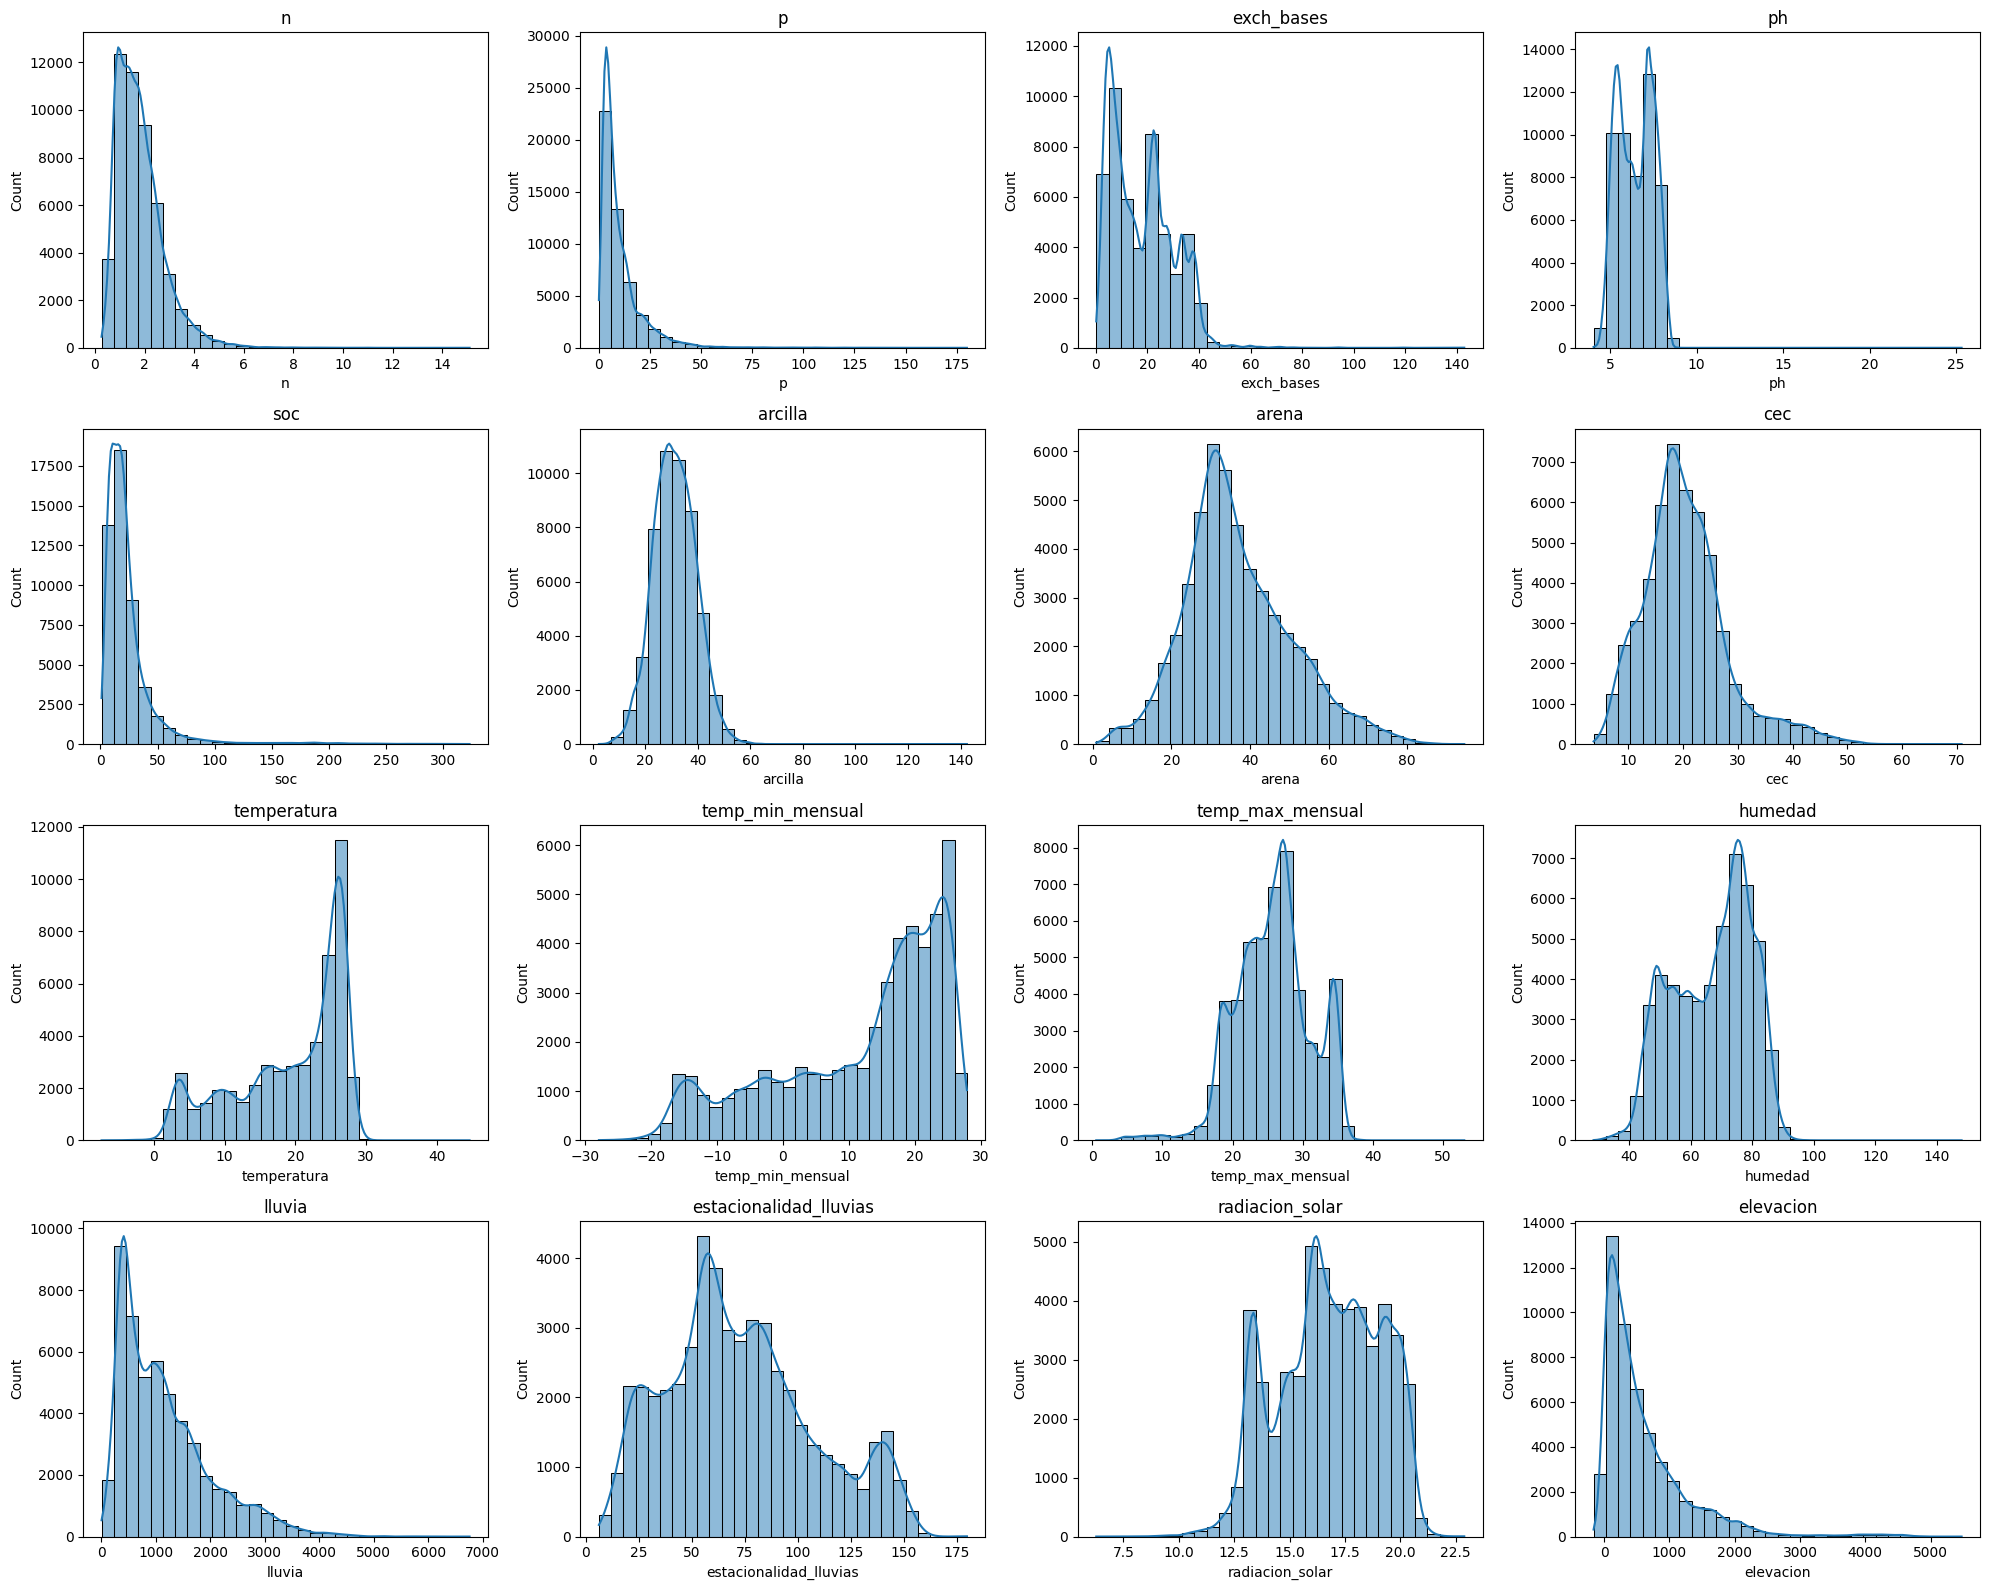

In [ ]:
num_cols = [
    'n', 'p', 'exch_bases', 'ph', 'soc', 'arcilla', 'arena', 'cec',
    'temperatura', 'temp_min_mensual', 'temp_max_mensual', 'humedad',
    'lluvia', 'estacionalidad_lluvias', 'radiacion_solar', 'elevacion'
]

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], bins=30)
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

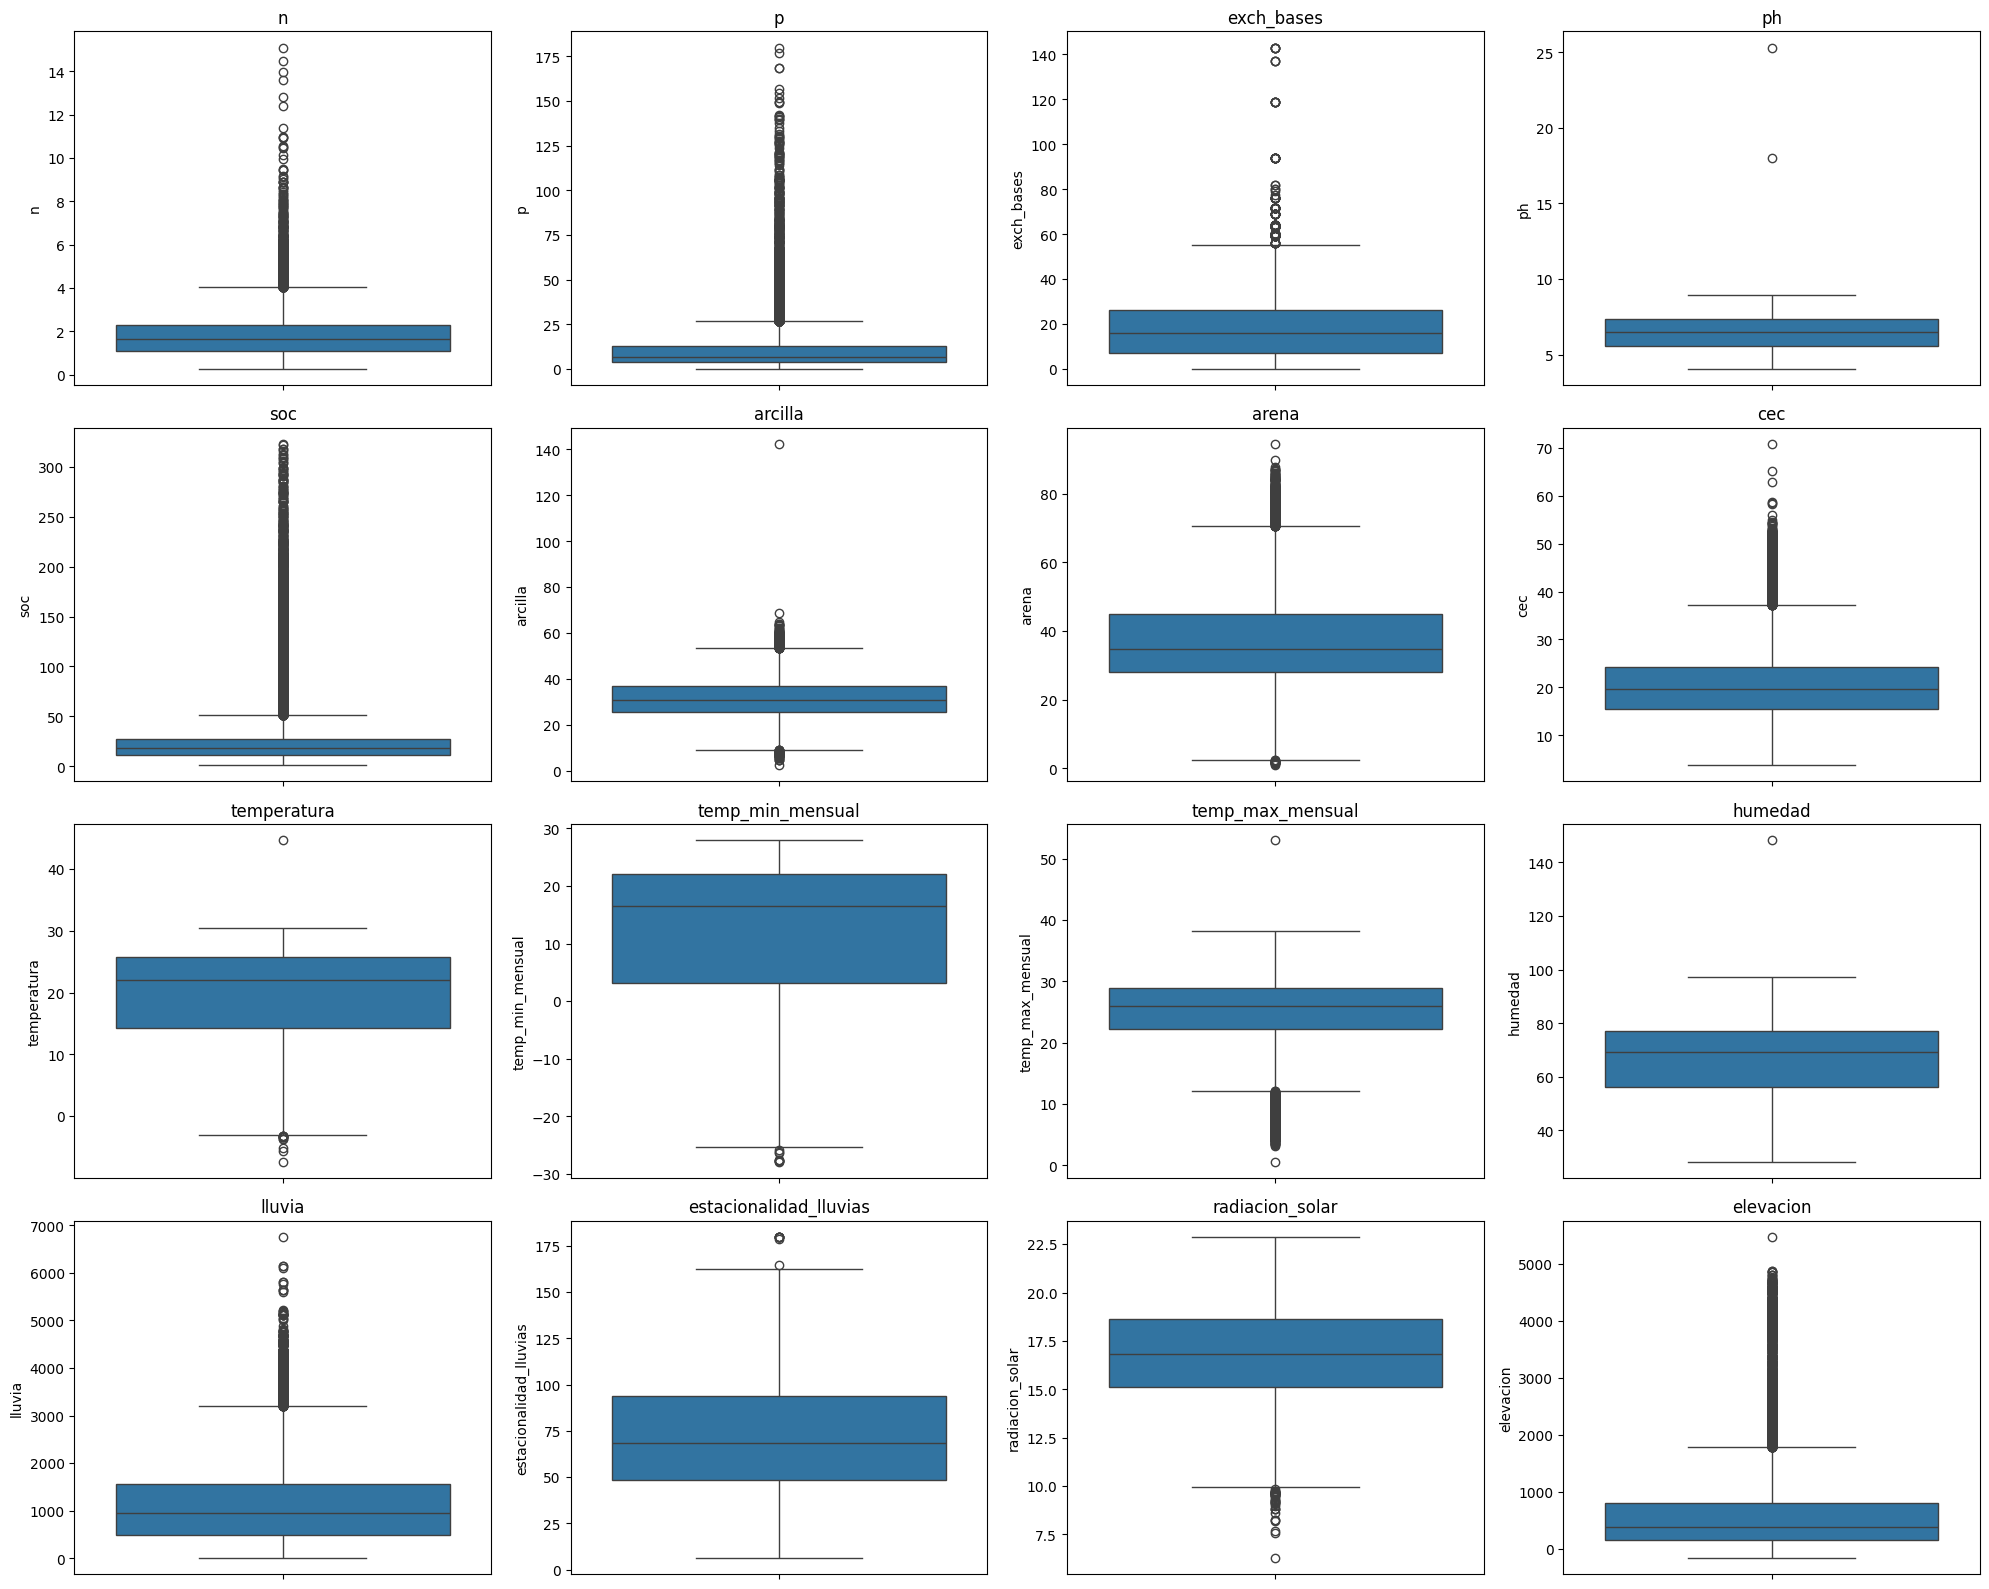

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

In [ ]:
for col in num_cols:
    print(f"{col}: {outliers_iqr(df[col]).sum()} outliers según IQR")

n: 1483 outliers según IQR
p: 3453 outliers según IQR
exch_bases: 181 outliers según IQR
ph: 2 outliers según IQR
soc: 3665 outliers según IQR
arcilla: 292 outliers según IQR
arena: 849 outliers según IQR
cec: 2162 outliers según IQR
temperatura: 14 outliers según IQR
temp_min_mensual: 9 outliers según IQR
temp_max_mensual: 535 outliers según IQR
humedad: 1 outliers según IQR
lluvia: 1360 outliers según IQR
estacionalidad_lluvias: 8 outliers según IQR
radiacion_solar: 41 outliers según IQR
elevacion: 2825 outliers según IQR


#### 1.2.3 Distribución de la variable objetivo (`Clase`)

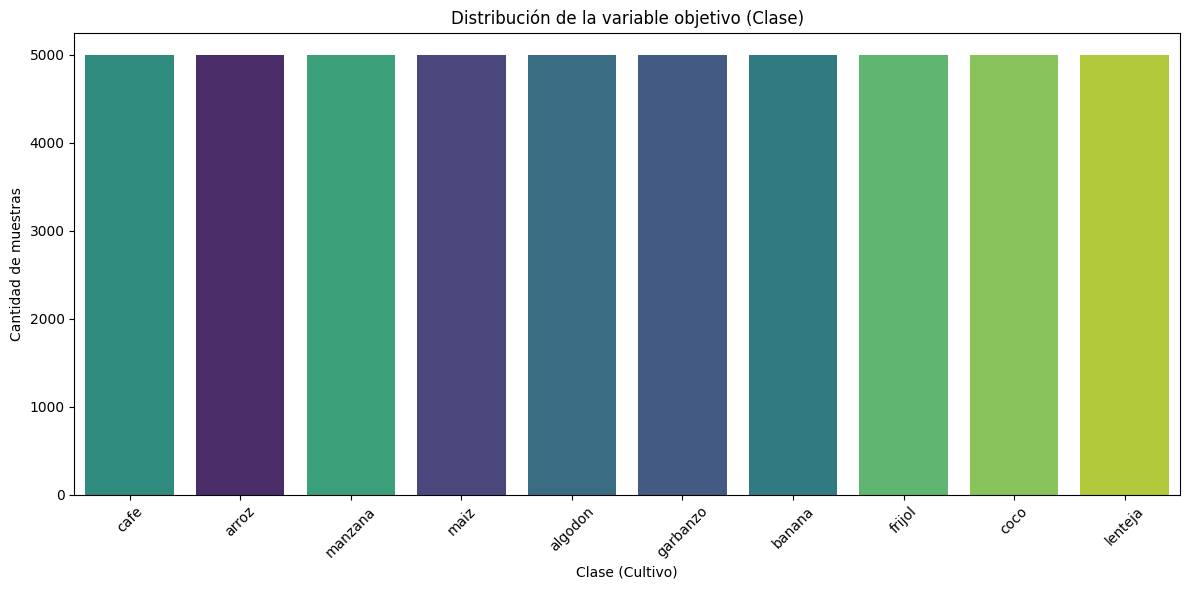

Conteo de muestras por clase:
clase
cafe        5002
arroz       5001
manzana     5001
maiz        5000
algodon     5000
garbanzo    5000
banana      5000
frijol      5000
coco        5000
lenteja     5000
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='clase', order=df['clase'].value_counts().index, palette='viridis', hue='clase', legend=False)
plt.title('Distribución de la variable objetivo (Clase)')
plt.xlabel('Clase (Cultivo)')
plt.ylabel('Cantidad de muestras')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Mostrar los conteos exactos por clase
print("Conteo de muestras por clase:")
print(df['clase'].value_counts())

#### 1.2.2 Análisis de correlaciones

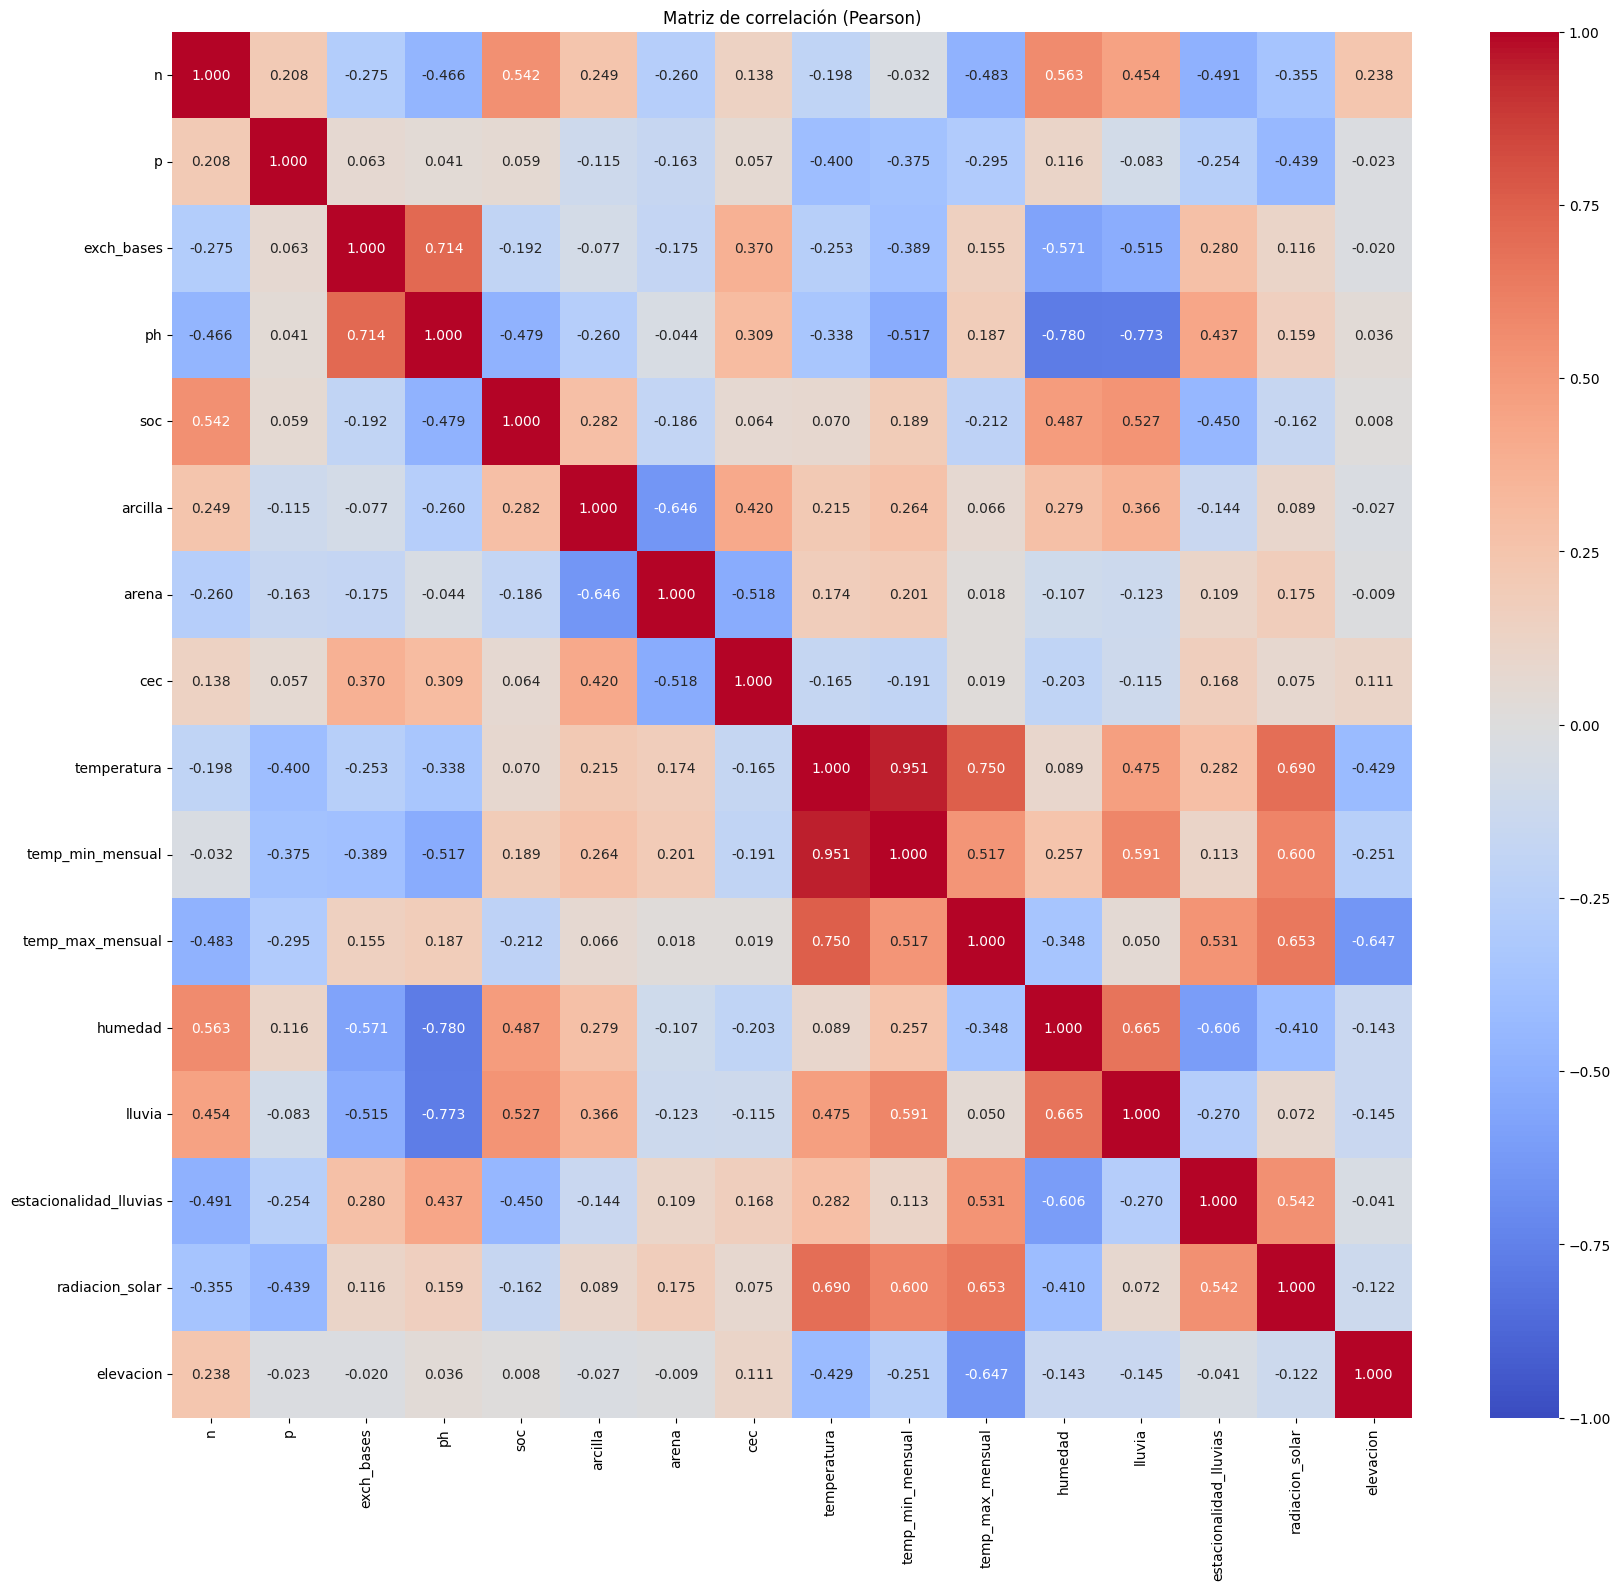

In [ ]:
plt.figure(figsize=(20, 18))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación (Pearson)")
plt.show()

### 1.3 Detección y tratamiento de problemas del dataset

#### 1.3.1 Valores faltantes
* Indicar en qué columnas se encuentran.
* Indicar la estrategia utilizada (eliminación, imputación por media/mediana, etc.) y **justificar la decisión**.

#### 1.3.2 Registros duplicados
* Indicar cuántos son y qué se hace con ellos.

#### 1.3.3 Posibles outliers
* Detectar y reportar.

Para tratar los outliers sin eliminar registros (lo cual implicaría una gran pérdida de datos dada la cantidad), aplicaremos una técnica de **capping (Winsorización)**. Esta técnica limita los valores extremos a los umbrales definidos por el Rango Intercuartílico (IQR), ayudando especialmente a modelos sensibles a la escala y a los extremos como SVM.

In [ ]:
# Tratamiento de outliers mediante Capping (Winsorización) basado en IQR
def cap_outliers_iqr(df_in, col):
    q1 = df_in[col].quantile(0.25)
    q3 = df_in[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Recortar (clip) los valores a los umbrales
    df_in[col] = df_in[col].clip(lower=lower_bound, upper=upper_bound)
    return df_in

# Aplicamos el capping a todas las variables numéricas
for col in num_cols:
    df = cap_outliers_iqr(df, col)

print("Tratamiento de outliers completado.")
print("Verificando la nueva cantidad de outliers:")
for col in num_cols:
    print(f"{col}: {outliers_iqr(df[col]).sum()} outliers según IQR")

Tratamiento de outliers completado.
Verificando la nueva cantidad de outliers:
n: 0 outliers según IQR
p: 0 outliers según IQR
exch_bases: 0 outliers según IQR
ph: 0 outliers según IQR
soc: 0 outliers según IQR
arcilla: 0 outliers según IQR
arena: 0 outliers según IQR
cec: 0 outliers según IQR
temperatura: 0 outliers según IQR
temp_min_mensual: 0 outliers según IQR
temp_max_mensual: 0 outliers según IQR
humedad: 0 outliers según IQR
lluvia: 0 outliers según IQR
estacionalidad_lluvias: 0 outliers según IQR
radiacion_solar: 0 outliers según IQR
elevacion: 0 outliers según IQR


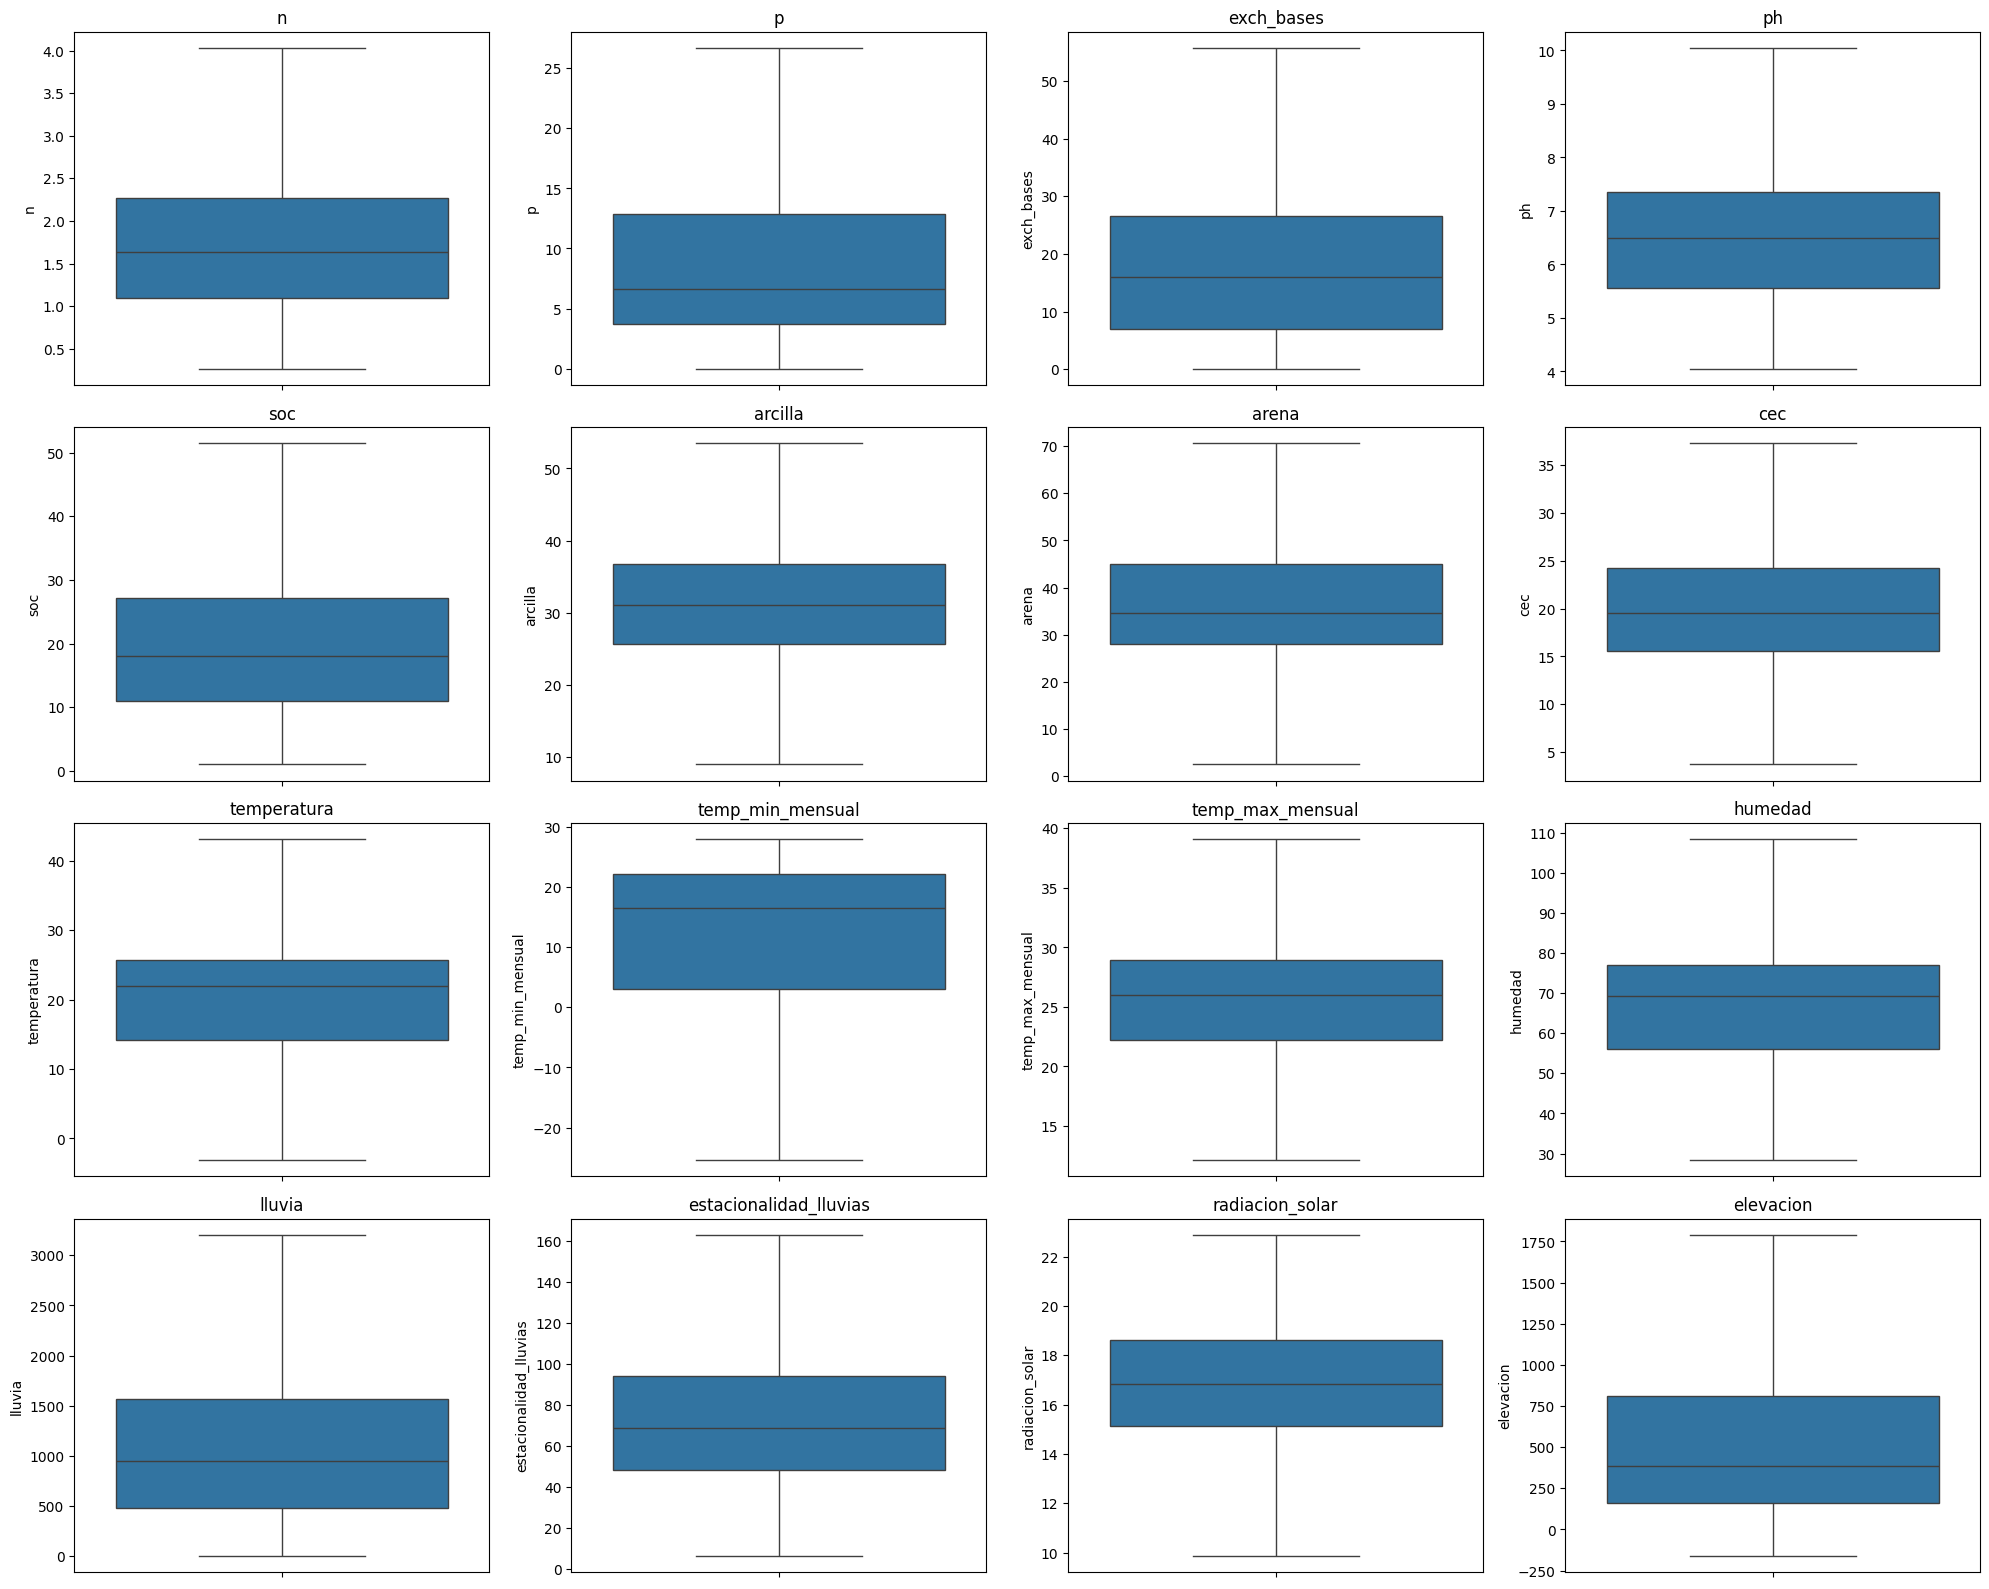

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

### 1.4 Estandarización de las características numéricas
* `StandardScaler` (SVM es sensible a la escala de las variables).

### 1.5 Codificación de la variable objetivo
* `LabelEncoder`, si corresponde.

## 2. SVM con kernel lineal

> **Consigna:** predecir `Clase` con `SVC(kernel='linear')`, explorando el parámetro de regularización `C` con **al menos 5 valores en escala logarítmica** (ej.: 0.01, 0.1, 1, 10, 100). Evaluar con validación cruzada estratificada `k=5` (`StratifiedKFold`) sobre todo el conjunto de datos limpio.

### 2.1 Configuración de la validación cruzada

### 2.2 Exploración del parámetro `C`

### 2.3 Resultados
* Precision (weighted), Recall (weighted) y Accuracy: **media ± desviación estándar** de los 5 folds.
* Se usa el promedio *weighted* porque el dataset presenta un leve desbalance entre clases.


### 2.4 Selección de la mejor configuración y justificación

## 3. SVM con kernel gaussiano (RBF)

> **Consigna:** predecir `Clase` con `SVC(kernel='rbf')`, explorando `C` y `gamma` con **al menos 4 valores cada uno en escala logarítmica** (ej.: C = {0.1, 1, 10, 100}, gamma = {0.001, 0.01, 0.1, 1}). Evaluar cada combinación con validación cruzada estratificada `k=5`.

### 3.1 Exploración de `C` y `gamma`

### 3.2 Resultados
* Precision (weighted), Recall (weighted) y Accuracy: media ± desviación estándar.
* Presentar en **tabla o heatmap** para visualizar la interacción entre `C` y `gamma`.

### 3.3 Selección de la mejor configuración y justificación

## 4. Random Forest

> **Consigna:** predecir `Clase` con `RandomForestClassifier`, explorando `n_estimators` (al menos 4 valores, ej.: 50, 100, 200, 500) y `max_depth` (al menos 4 valores, ej.: 5, 10, 20, None). Evaluar cada combinación con validación cruzada estratificada `k=5`.

### 4.1 Exploración de `n_estimators` y `max_depth`

### 4.2 Resultados
* Precision (weighted), Recall (weighted) y Accuracy: media ± desviación estándar.

### 4.3 Importancia de las variables (`feature_importances_`) del mejor modelo

### 4.4 Selección de la mejor configuración y justificación

## 5. Comparación de modelos


### 5.1 Tabla comparativa
* SVM lineal vs. SVM RBF vs. Random Forest, con las métricas de la **mejor configuración** de cada algoritmo.

### 5.2 Matrices de confusión
* Una por cada mejor modelo (usando un fold de la validación cruzada **o** un split adicional 80/20 con `random_state=13`).

### 5.3 Selección del modelo más adecuado
Justificar considerando:
* Métricas obtenidas
* Estabilidad entre folds (desviación estándar)
* Interpretabilidad
* Tiempo de entrenamiento